# Data Exploration Primer

**Your task:** explore historical house sales and explain what the data can tell
us about prices. At the end, you will shortlist sale records for a buyer with
specific requirements.

By the end of this primer, you should be able to:

- inspect a table and distinguish measurements, categories, identifiers, and dates;
- choose and interpret simple summaries and plots;
- filter records, create a new measure, and rank a subset;
- support a finding with evidence and acknowledge a limitation.

## How to work through this notebook

Work through **Exercises 1–4** in order. The extensions at the end are optional.
Read and run the **worked examples**, then complete cells marked **Your turn**.
When a question asks for a prediction, write it **before** running the next cell.
Predictions are not graded for being correct; explain what you learned afterwards.

Write short answers in Markdown cells: two or three sentences are usually enough.
To edit a Markdown cell, double-click it; run it to display the formatted text.

A pandas **DataFrame** is a table. `houses["price"]` selects one column, and
`houses[["price", "grade"]]` selects a table containing two columns.
A method such as `.head()` performs an operation on the object before the dot.

**Before submitting:** restart the kernel and run all cells from top to bottom.
Incomplete tasks must be completed even if they do not raise an error.

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

## The dataset and setup

Keep **`kc_house_data.csv` in the same folder as this notebook**. If using
Google Colab, upload the CSV into the session's files before running the next cell.
Use a Python environment with `pandas` and `matplotlib` installed.

The file contains **21,613 sale records** in **King County, Washington, USA**,
dated **2 May 2014 to 27 May 2015**. Each row is a recorded sale: the same house
identifier can occur more than once. These are historical transactions, not
current listings or a census of every house in the county.

In [ ]:
# The two paths support starting Jupyter in this folder or in the project folder.
possible_paths = [Path("kc_house_data.csv"), Path("Primer Assignments") / "kc_house_data.csv"]
data_path = next((path for path in possible_paths if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Put kc_house_data.csv beside this notebook, then run this cell again.")

houses = pd.read_csv(data_path)
houses.head()  # Jupyter displays the last expression in a cell.

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


### A small data dictionary

We will focus on the following columns; you do not need to use every column.

| Column | Meaning and units | Important detail |
|---|---|---|
| `id` | House identifier | A label, not a measurement; repeated sales can share an ID. |
| `date` | Sale date, stored as text | For example, `20141013T000000` means 13 October 2014. |
| `price` | Recorded sale price, USD | Historical price, not a current valuation. |
| `bedrooms` | Number of bedrooms | A numerical count. |
| `bathrooms` | Recorded bathroom count | Includes fractional values for partial bathrooms. |
| `floors` | Recorded number of floors | Can include fractional values. |
| `sqft_living` | Living area, square feet | Different from lot area (`sqft_lot`). |
| `zipcode` | Postal ZIP code | An unordered category, even when stored as an integer. |
| `grade` | Ordered construction/design rating | Larger values indicate a higher rating; equal steps need not mean equal quality differences. |
| `yr_renovated` | Recorded renovation year | In this teaching copy, 0 means no renovation year is recorded. |
| `lat`, `long` | Latitude and longitude, degrees | Coordinates of the property. |

`waterfront` is a 0/1 waterfront indicator, `condition` is an ordered condition
rating, and `sqft_basement` is basement area in square feet (0 means no basement
area is recorded). These columns appear in the optional extensions.

## Exercise 1 — Understand the table and its summaries

**Worked example:** `.shape` gives the number of rows and columns, `.columns`
lists their names, and `.dtypes` shows their Python storage types.
Storage type does not determine a variable's statistical meaning.

In [ ]:
print("Rows and columns:", houses.shape)
print("Column names:", houses.columns.tolist())
houses.dtypes

Rows and columns: (21613, 21)
Column names: ['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


,0
id,int64
date,object
price,float64
bedrooms,int64
bathrooms,float64
sqft_living,int64
sqft_lot,int64
floors,float64
waterfront,int64
view,int64


**Your turn — classify by meaning.** Complete the table. Use the roles
*numerical measurement*, *numerical count*, *unordered category*,
*ordered category*, *identifier*, or *date/time*.

| Column | Your classification | A useful summary, and why |
|---|---|---|
| `sqft_living` | numerical measurement | Number of square feet available inside the house, continous |
| `bedrooms` | numerical count | Number of bedrooms, discrete |
| `zipcode` | identifier | Self-explanatory |
| `grade` | ordered category | A discrete numerical value describing the quality of the building. Ordered from 1 (worst) to 13 (best) |
| `id` | identifier | Unique number for each house |
| `date` | date/time | Self-explanatory |

Why would the average of the ZIP codes or house identifiers be unhelpful?

**Your explanation:** because ZIP codes or house indentifiers aren't numerical variables. A mean of ZIP codes of some houses wouldn't necessarily describe a location in the geographical center of those houses.

**Worked example — check missing values.** `.isna()` identifies missing entries;
`.sum()` counts them in each column. A zero missing-value count does not prove
that every value is correct or informative.

In [ ]:
houses.isna().sum()

,0
id,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0


**Worked example — numerical summaries.** `.describe()` shows the number of
non-missing values, mean, standard deviation, minimum, quartiles, and maximum.
The 50% value is the **median**: half the observations are at or below it.

Read the table below. Notice the units and the difference between a typical
value and an extreme value.

In [ ]:
houses[["price", "sqft_living", "bedrooms", "yr_renovated"]].describe().round(2)

,price,sqft_living,bedrooms,yr_renovated
count,21613.00,21613.00,21613.00,21613.00
mean,540088.14,2079.90,3.37,84.40
std,367127.20,918.44,0.93,401.68
min,75000.00,290.00,0.00,0.00
25%,321950.00,1427.00,3.00,0.00
50%,450000.00,1910.00,3.00,0.00
75%,645000.00,2550.00,4.00,0.00
max,7700000.00,13540.00,33.00,2015.00


**Your turn — investigate three summaries.** In the next code cell:

1. Calculate the mean and median price using `.mean()` and `.median()`.
2. Use `.value_counts().head()` on `yr_renovated` to find its most common values.
3. Inspect rows with an unusually high bedroom count. The example below shows
   how to select records satisfying one condition; it does not alter the data.

Then answer the questions underneath. Do not remove unusual observations
automatically: investigating them is part of exploration.

In [ ]:
# TODO: calculate and print the mean and median sale price.
# Hint: houses["price"].mean() and houses["price"].median()

print("mean: ")
houses["price"].mean().round(2)
print("median: ")
houses["price"].median()

# TODO: show the five most common values of yr_renovated.
# Hint: houses["yr_renovated"].value_counts().head()
houses["yr_renovated"].value_counts().head()

for col in houses.columns:
    print(f"\n--- Count of occurences of values in column: {col} ---")
    houses[col].value_counts()

# Supplied example: a Boolean condition selects records with more than 10 bedrooms.
# houses.loc[houses["bedrooms"] > 10, ["id", "bedrooms", "sqft_living", "price"]]

mean: 


np.float64(540088.14)

median: 


450000.0

,count
yr_renovated,
0,20699
2014,91
2013,37
2003,36
2005,35


...

,count
long,
-122.290,116
-122.300,111
-122.362,104
-122.291,100
-122.372,99
...,...
-121.316,1
-121.941,1
-121.480,1



--- Count of occurences of values in column: sqft_living15 ---


,count
sqft_living15,
1540,197
1440,195
1560,192
1500,181
1460,169
...,...
2513,1
2725,1
1955,1



--- Count of occurences of values in column: sqft_lot15 ---


,count
sqft_lot15,
5000,427
4000,357
6000,289
7200,211
4800,145
...,...
5259,1
3836,1
5009,1


**Mean and median:** Which price summary would you use to describe a typical
recorded sale? Give the two values and explain your choice.

I would use the median, because the mean is sensitive to outliers.

**Zeros and missing values:** Why does the mean of `yr_renovated` not describe
a typical renovation year? How could you summarize this column more usefully?

Because the value '0' is used to indicate that the house wasn't renovated. If we want to get useful statistics out of `yr_renovated`, we should remove all '0' values first.

**Unusual values:** Identify one value you would investigate. What information
would you need before deciding to correct or remove it?

I would investigate the '0' values in `yr_renovated`. I would need to check its meaning before deciding if I should remove them.

## Exercise 2 — Explore distributions and relationships

A **histogram** groups numerical values into intervals and shows how many
observations fall in each interval. A **scatterplot** shows two values for each
record, helping us examine an association.

**Predict first:** Do you expect prices to be evenly distributed? Do you expect
houses with more living area to have higher recorded sale prices? Explain briefly.

I expect cheaper houses to dominate, because there are more people with an average income than millionaires. I expect a positive correlation between living area and the sale price.


**Worked examples.** `fig` is the whole figure and `ax` is its plotting area.
We create a plot, add labels with units, and call `plt.show()` to display it.
In the scatterplot, `s` controls point size and `alpha` controls transparency:
small, translucent points help when many observations overlap.

(array([5.722e+03, 9.161e+03, 4.138e+03, 1.361e+03, 5.160e+02, 2.710e+02,
        1.730e+02, 8.300e+01, 6.000e+01, 4.600e+01, 1.600e+01, 2.800e+01,
        1.200e+01, 6.000e+00, 8.000e+00, 1.000e+00, 1.000e+00, 2.000e+00,
        1.000e+00, 1.000e+00, 2.000e+00, 1.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 1.000e+00, 1.000e+00, 0.000e+00, 1.000e+00]),
 array([  75000.        ,  329166.66666667,  583333.33333333,
         837500.        , 1091666.66666667, 1345833.33333333,
        1600000.        , 1854166.66666667, 2108333.33333333,
        2362500.        , 2616666.66666667, 2870833.33333333,
        3125000.        , 3379166.66666667, 3633333.33333333,
        3887500.        , 4141666.66666667, 4395833.33333333,
        4650000.        , 4904166.66666667, 5158333.33333333,
        5412500.        , 5666666.66666667, 5920833.33333333,
        6175000.        , 6429166.66666667, 6683333.33333333,
        6937500.        , 7191666.66666667, 7445833.33333333,
        

Text(0.5, 0, 'Recorded sale price (USD)')

Text(0, 0.5, 'Number of sale records')

Text(0.5, 1.0, 'Distribution of recorded sale prices')

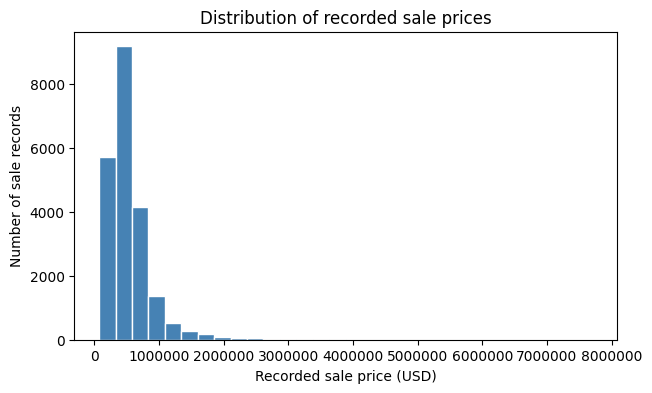

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(houses["price"], bins=30, color="steelblue", edgecolor="white")
ax.set_xlabel("Recorded sale price (USD)")
ax.set_ylabel("Number of sale records")
ax.set_title("Distribution of recorded sale prices")
ax.ticklabel_format(style="plain", axis="x")
plt.show()

Text(0.5, 0, 'Living area (square feet)')

Text(0, 0.5, 'Recorded sale price (USD)')

Text(0.5, 1.0, 'Living area and sale price')

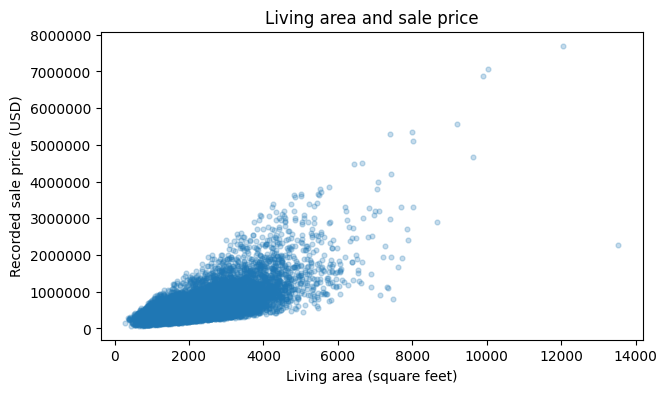

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(houses["sqft_living"], houses["price"], s=12, alpha=0.25)
ax.set_xlabel("Living area (square feet)")
ax.set_ylabel("Recorded sale price (USD)")
ax.set_title("Living area and sale price")
ax.ticklabel_format(style="plain", axis="y")
plt.show()

**Your turn — adapt the plotting pattern.** Choose `bathrooms` or `bedrooms`,
and make a scatterplot of that variable against price. Give it a title and
meaningful axis labels. You can copy and modify the previous example.

Make one prediction before running your plot. If the points overlap heavily,
use a smaller `s` or `alpha`; explain why an empty-looking region or a dense
cluster might be difficult to interpret.

Chose `bedrooms`.

Text(0.5, 0, 'Number of bedrooms')

Text(0, 0.5, 'Recorded sale price (USD)')

Text(0.5, 1.0, 'Number of bedrooms and sale price')

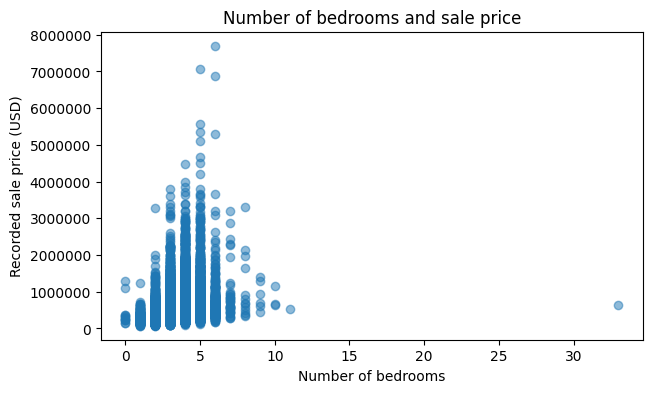

In [ ]:
x_column = "bedrooms"  # You may choose "bedrooms" instead.

# TODO: make a scatterplot of houses[x_column] against houses["price"].
# Include a title, axis labels with units, and plt.show().
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(houses['bedrooms'], houses['price'], alpha=0.5)
ax.set_xlabel("Number of bedrooms")
ax.set_ylabel("Recorded sale price (USD)")
ax.set_title("Number of bedrooms and sale price")
ax.ticklabel_format(style="plain", axis="y")
plt.show()

In [ ]:
houses.loc[houses["bedrooms"] == 33]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
15870,2402100895,20140625T000000,640000.0,33,1.75,1620,6000,1.0,0,0,...,7,1040,580,1947,0,98103,47.6878,-122.331,1330,4700


**Distribution:** How does the price histogram help explain the difference
between the mean and median from Exercise 1?

We can see there are some outliers with high sale price, which skews the mean.

**Relationship:** Describe the direction and spread in your chosen scatterplot.
Does the trend describe every sale? Support your answer with something visible
in the plot.

The scatterplot shows a generally positive relationship. Homes with more bedrooms tend to sell for higher prices, particularly between 1 and 6 bedrooms. However, prices vary widely for the same bedroom count, especially around 4–6 bedrooms.

One thing to note is that the 33 bedrooms in that one house is probably a typo. The house has a lower than median living space in sqrft, but it somehow has 33 bedrooms?

**Limits:** A larger house may also differ in location, condition, or grade.
Why does an association with price not establish that changing one feature
would cause the price to change? Suggest one other feature to consider.

Because of other variables. An association does not prove causation because other factors, such as location or condition, may influence both the feature and the sale price. Houses with more bedrooms might cost more partly because they are in more expensive areas, so adding a bedroom would not necessarily produce the same price increase.
One other feature to consider is living area, since houses with the same number of bedrooms can differ in size.

## Exercise 3 — Compare prices across ordered categories

`grade` is an ordered rating. First examine **how many sales are in each grade**;
comparing a group with very few records to a large group requires care.

**Worked example:** `.value_counts()` counts records in each category and
`.sort_index()` puts grades in their numerical order. Here a bar chart is
appropriate because each bar represents a distinct category.

grade
1        1
3        3
4       29
5      242
6     2038
7     8981
8     6068
9     2615
10    1134
11     399
12      90
13      13
Name: count, dtype: int64


<Axes: xlabel='grade'>

Text(0.5, 0, 'Construction/design grade')

Text(0, 0.5, 'Number of sale records')

Text(0.5, 1.0, 'Number of recorded sales by grade')

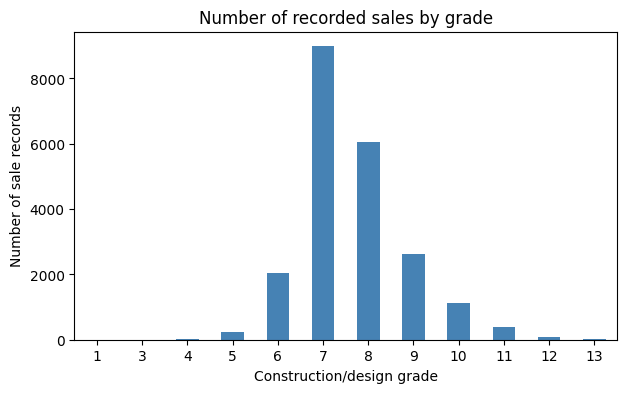

In [ ]:
grade_counts = houses["grade"].value_counts().sort_index()
print(grade_counts)

fig, ax = plt.subplots(figsize=(7, 4))
grade_counts.plot.bar(ax=ax, color="steelblue", rot=0)
ax.set_xlabel("Construction/design grade")
ax.set_ylabel("Number of sale records")
ax.set_title("Number of recorded sales by grade")
plt.show()

**Your turn:** use the scatterplot pattern to plot `grade` on the horizontal
axis and `price` on the vertical axis. This will give a useful comparison
with the boxplot below.

Text(0.5, 0, 'House grade')

Text(0, 0.5, 'Recorded sale price (USD)')

Text(0.5, 1.0, 'House grade and price')

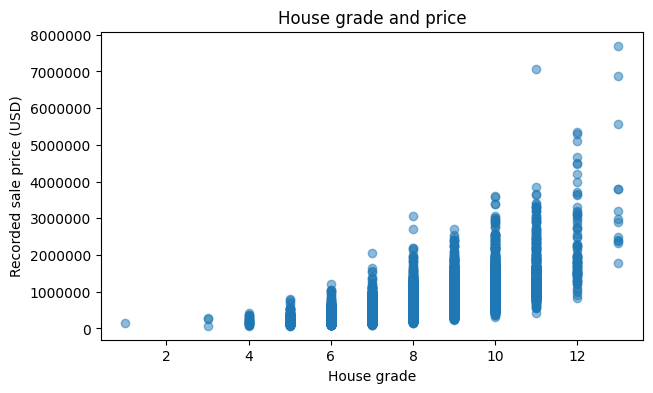

In [ ]:
# TODO: plot grade against price, including readable labels and a title.
# Hint: adapt the worked scatterplot from Exercise 2.
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(houses['grade'], houses['price'], alpha=0.5)
ax.set_xlabel("House grade")
ax.set_ylabel("Recorded sale price (USD)")
ax.set_title("House grade and price")
ax.ticklabel_format(style="plain", axis="y")
plt.show()

**Worked example — a boxplot for each grade.** A boxplot summarizes a numerical
distribution. The line inside a box is the **median**; the bottom and top are
the 25th and 75th percentiles, so the box contains the middle 50% of observations.
The box height is the **interquartile range (IQR)**.

In this plot, whiskers extend to the most extreme observations still within
1.5 IQR of the box. Points beyond the whiskers are flagged as outliers.
They are not automatically errors or evidence that a house was overpriced.

pandas creates the groups and labels them with their actual grade values.

<Axes: title={'center': 'price'}, xlabel='grade'>

Text(0.5, 0.98, '')

Text(0.5, 1.0, 'Recorded sale price distributions by grade')

Text(0.5, 0, 'Construction/design grade')

Text(0, 0.5, 'Recorded sale price (USD)')

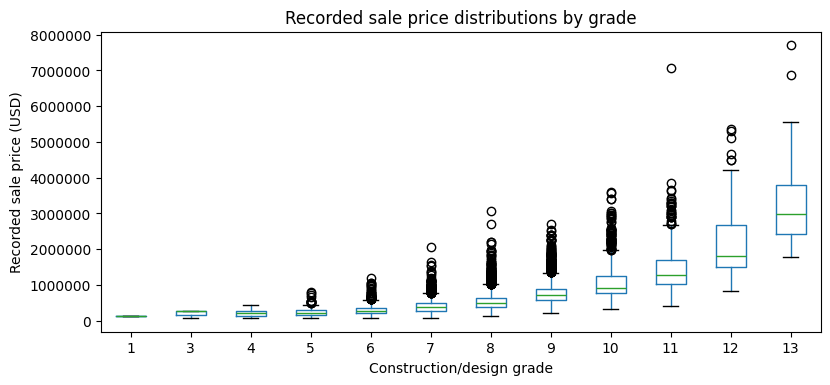

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
houses.boxplot(column="price", by="grade", ax=ax, grid=False)
fig.suptitle("")  # Remove the extra title that pandas adds automatically.
ax.set_title("Recorded sale price distributions by grade")
ax.set_xlabel("Construction/design grade")
ax.set_ylabel("Recorded sale price (USD)")
ax.ticklabel_format(style="plain", axis="y")
plt.show()

In [ ]:
len(houses.loc[houses['grade'] == 13])

13

**Compare:** What does the boxplot make easier to see than your grade–price
scatterplot? Describe a pattern in the medians and a pattern in the spread.

The boxplot makes it easier to see how many outliers there are for each grade. The bigger the grade, the higher is the median price of the houses for that grade. The spread also increases with the grade.

**Check the group sizes:** Name a grade with few records. Why should a claim
about its price distribution be cautious?

Grade 13 has very few records (13). With very few records, individual sales can strongly influence the median and spread, so the observed distribution may not represent typical prices for that grade.

**Critique:** A student says, "All points above the whiskers are overpriced
houses." Explain why the plot does not support that conclusion.

Because there might be other variables at play. For example, a house with the same build grade might have a bigger living area than most others in that grade, therefore having a bigger price than most in that grade.

## Exercise 4 — Shortlist sales that meet a buyer's requirements

A buyer wants a house with **exactly 3 bedrooms, exactly 2 bathrooms, and exactly
2 floors**. Use historical sales to explore possible trade-offs; these houses
are not necessarily for sale today.

**Worked example — filtering:** a Boolean mask contains `True` for records
that satisfy a condition. `.loc[mask, columns]` selects those rows and columns.
When combining conditions, put each in parentheses and use `&` for **and**
(`|` means **or**). `.copy()` creates a separate table for the subset.

In [ ]:
large_mask = houses["sqft_living"] >= 2000
large_sales = houses.loc[large_mask, ["id", "price", "sqft_living"]].copy()
print("Sale records with at least 2,000 square feet:", len(large_sales))
large_sales.head()

Sale records with at least 2,000 square feet: 10004


,id,price,sqft_living
1,6414100192,538000.0,2570
5,7237550310,1225000.0,5420
10,1736800520,662500.0,3560
15,9297300055,650000.0,2950
21,2524049179,2000000.0,3050


**Your turn — combine three conditions.** Create `matching_houses`, keeping
**all columns**, using the buyer's exact requirements. Start from `houses`,
combine the three conditions, and use `.copy()`.

Replace `None` below with your selection. `None` is a placeholder, not an answer.
Then run the supplied checkpoint. It should confirm that the selected records
satisfy all three requirements.

In [ ]:
# There's also a possibility of having fractional bathrooms, but 2.5 would mean we have 2 bathrooms + only toilet. So we want only discrete values, not [2,3] interval for example
matching_houses = houses[(houses["bedrooms"] == 3) & (houses["bathrooms"] == 2) & (houses["floors"] == 2)].copy()
buyers_houses = matching_houses.copy()
buyers_houses.head()

# Hint for one condition: (houses["bedrooms"] == 3)
# Join conditions with & and select rows using houses.loc[...].copy().

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
16,1875500060,20140731T000000,395000.0,3,2.0,1890,14040,2.0,0,0,...,7,1890,0,1994,0,98019,47.7277,-121.962,1890,14018
150,3362900810,20140820T000000,532170.0,3,2.0,1360,3090,2.0,0,0,...,8,1360,0,1990,0,98103,47.6838,-122.353,1500,3090
294,9297300045,20140709T000000,550000.0,3,2.0,1970,4166,2.0,0,3,...,8,1270,700,1929,0,98126,47.5717,-122.375,2390,4166
365,723099065,20150130T000000,465000.0,3,2.0,1840,40438,2.0,0,0,...,7,1840,0,1994,0,98045,47.4853,-121.709,1380,44049
462,8944290160,20141104T000000,230000.0,3,2.0,1510,3413,2.0,0,0,...,7,1510,0,1985,0,98031,47.3912,-122.167,1570,3777


In [ ]:
# Supplied checkpoint: run this after completing your filter.
if matching_houses is None:
    print("INCOMPLETE: create matching_houses in the previous task cell.")
else:
    assert len(matching_houses) > 0, "Your selection is empty; check the conditions."
    assert (matching_houses["bedrooms"] == 3).all(), "Check the bedroom condition."
    assert (matching_houses["bathrooms"] == 2).all(), "Check the bathroom condition."
    assert (matching_houses["floors"] == 2).all(), "Check the floor condition."
    print("Checkpoint passed: every selected record satisfies the requirements.")
    print("Number of matching sale records:", len(matching_houses))

Checkpoint passed: every selected record satisfies the requirements.
Number of matching sale records: 154


**Your turn — summarize the selection.** Report the number of matching sales
and use `.describe()` on their `price` and `sqft_living` columns. Compare the
subset's median price with the median for the full dataset from Exercise 1.

In [ ]:
# TODO: summarize matching_houses once you have completed the filter.
# Hint: matching_houses[["price", "sqft_living"]].describe()
buyers_houses[["price", "sqft_living"]].describe().round(2)

,price,sqft_living
count,154.00,154.00
mean,514498.61,1850.28
std,249766.08,547.59
min,209000.00,1020.00
25%,376975.00,1452.50
50%,464000.00,1700.00
75%,589462.50,2127.50
max,1755000.00,3650.00


**Your turn — create a measure and rank the subset.**

Define **price per square foot = price / living area**, measured in USD per
square foot. For example, a sale for 300,000 USD with 2,000 square feet has a value
of 150 USD per square foot. **Smaller values mean a lower price per unit of space.**

1. Add a column called `price_per_sqft` to `matching_houses` using column-wise
   division: the operation calculates one ratio for each row.
2. Use `.sort_values("price_per_sqft")` and `.head(5)` to create `shortlist`.
   **Keep all columns**, so the checkpoint can verify your selection.
3. Show a readable table containing `id`, `date`, `price`, `sqft_living`,
   `price_per_sqft`, and `grade`. An ID and date together identify the sale.

Continue working with `matching_houses` when ranking: the buyer's requirements
still apply. Sorting by the ratio changes the order, not the requirements.

In [ ]:
matching_houses["price_per_sqft"] = matching_houses["price"] / matching_houses["sqft_living"]
shortlist = matching_houses.sort_values("price_per_sqft").sort_values("price_per_sqft").head(5)
shortlist

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,price_per_sqft
9704,7452500565,20140829T000000,260000.0,3,2.0,2710,5000,2.0,0,0,...,2710,0,1951,0,98126,47.5188,-122.373,850,5000,95.940959
11258,7937600262,20140710T000000,379900.0,3,2.0,3110,44967,2.0,0,0,...,3020,90,1999,0,98058,47.4343,-122.082,2150,44967,122.154341
19880,3832050860,20150319T000000,210000.0,3,2.0,1580,4961,2.0,0,0,...,1580,0,2006,0,98042,47.3338,-122.053,2280,5000,132.911392
16014,5104450440,20141113T000000,252500.0,3,2.0,1810,10684,2.0,0,0,...,1810,0,1987,0,98058,47.4619,-122.153,2140,9657,139.502762
20906,3355400242,20141028T000000,274900.0,3,2.0,1936,6612,2.0,0,0,...,1936,0,2014,0,98001,47.2602,-122.246,1620,21600,141.993802


In [ ]:
matching_houses.describe().round(2)

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,price_per_sqft
count,1.540000e+02,154.00,154.0,154.0,154.00,154.00,154.0,154.00,154.00,154.00,...,154.00,154.00,154.00,154.00,154.00,154.00,154.00,154.00,154.00,154.00
mean,4.397177e+09,514498.61,3.0,2.0,1850.28,23678.95,2.0,0.01,0.36,3.44,...,1717.42,132.86,1969.78,284.86,98085.58,47.57,-122.25,1802.34,17545.12,280.17
std,2.849813e+09,249766.08,0.0,0.0,547.59,83324.02,0.0,0.08,0.92,0.71,...,527.47,248.09,34.65,700.06,48.81,0.14,0.15,453.21,40404.13,101.35
min,7.600057e+06,209000.00,3.0,2.0,1020.00,700.00,2.0,0.00,0.00,2.00,...,720.00,0.00,1900.00,0.00,98001.00,47.19,-122.52,850.00,886.00,95.94
25%,2.060901e+09,376975.00,3.0,2.0,1452.50,3414.75,2.0,0.00,0.00,3.00,...,1402.50,0.00,1942.25,0.00,98038.50,47.50,-122.36,1452.50,4020.00,204.66
50%,3.630010e+09,464000.00,3.0,2.0,1700.00,5868.50,2.0,0.00,0.00,3.00,...,1625.00,0.00,1984.50,0.00,98103.00,47.58,-122.30,1725.00,6278.00,268.22
75%,7.184074e+09,589462.50,3.0,2.0,2127.50,10800.25,2.0,0.00,0.00,4.00,...,1977.50,207.50,1997.50,0.00,98122.00,47.68,-122.15,2117.50,10392.25,338.35
max,9.829200e+09,1755000.00,3.0,2.0,3650.00,843309.00,2.0,1.00,4.00,5.00,...,3650.00,1120.00,2014.00,2014.00,98199.00,47.78,-121.71,3170.00,273992.00,743.64


In [ ]:
# Supplied checkpoint. It checks constraints, units, and ordering, not your explanation.
if matching_houses is None or shortlist is None:
    print("INCOMPLETE: finish both the filtering and ranking tasks.")
else:
    assert len(shortlist) == min(5, len(matching_houses)), "Check the shortlist length."
    assert (shortlist["bedrooms"] == 3).all(), "A shortlisted sale fails the bedroom requirement."
    assert (shortlist["bathrooms"] == 2).all(), "A shortlisted sale fails the bathroom requirement."
    assert (shortlist["floors"] == 2).all(), "A shortlisted sale fails the floor requirement."
    assert (shortlist["sqft_living"] > 0).all(), "Check the living areas before dividing."
    expected_ratios = shortlist["price"] / shortlist["sqft_living"]
    assert ((shortlist["price_per_sqft"] - expected_ratios).abs() < 0.000001).all(), "Check the ratio's numerator and denominator."
    assert shortlist["price_per_sqft"].is_monotonic_increasing, "Sort from lowest to highest ratio."
    assert shortlist.index.is_unique and shortlist.index.isin(matching_houses.index).all(), "Keep the original sale-row indexes when filtering and sorting."
    cutoff = (matching_houses["price"] / matching_houses["sqft_living"]).nsmallest(len(shortlist)).max()
    assert (shortlist["price_per_sqft"] <= cutoff + 0.000001).all(), "Some selected records have a lower ratio than a shortlisted record."
    print("Checkpoint passed: the shortlist contains the lowest ratios among matching sales.")

Checkpoint passed: the shortlist contains the lowest ratios among matching sales.


**Worked example — highlight a subset.** Once you have created the shortlist,
run the following cell. The grey points show all sales, the blue points show
matching sales, and the orange outlines show shortlisted sales.
All points use the same axes, allowing a direct comparison.

Text(0.5, 0, 'Living area (square feet)')

Text(0, 0.5, 'Recorded sale price (USD)')

Text(0.5, 1.0, 'Matching sales and the price-per-square-foot shortlist')

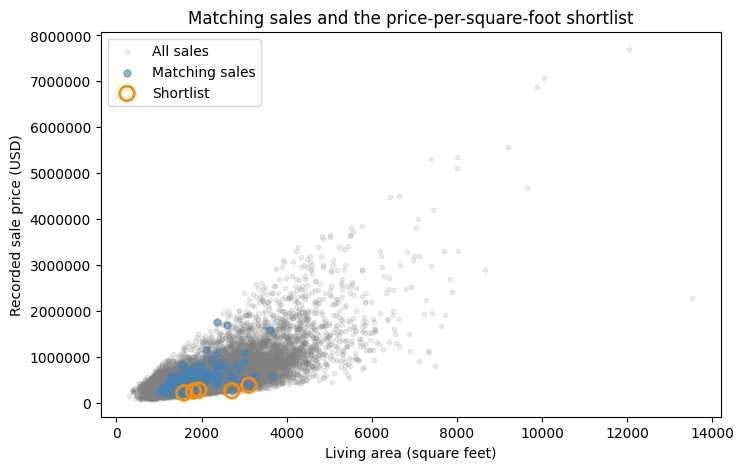

In [ ]:
if matching_houses is None or shortlist is None:
    print("INCOMPLETE: finish the selection and shortlist to display this plot.")
else:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(houses["sqft_living"], houses["price"], color="grey", s=10, alpha=0.15, label="All sales")
    ax.scatter(matching_houses["sqft_living"], matching_houses["price"], color="steelblue", s=25, alpha=0.6, label="Matching sales")
    ax.scatter(shortlist["sqft_living"], shortlist["price"], facecolors="none", edgecolors="darkorange", s=110, linewidths=2, label="Shortlist")
    ax.set_xlabel("Living area (square feet)")
    ax.set_ylabel("Recorded sale price (USD)")
    ax.set_title("Matching sales and the price-per-square-foot shortlist")
    ax.ticklabel_format(style="plain", axis="y")
    ax.legend()
    plt.show()

**Summarize:** How many sales match the requirements? How does their median
price compare with the full dataset's median?

154 sales match the requirements. Their median is 464000, while the full dataset's median is 450000, so it's 0.17 stddev bigger.

**Recommend:** Choose one shortlisted sale and identify it by ID and date.
Give its price, living area, and price per square foot. Explain one advantage
and one trade-off, using evidence from your table or plot.

```
ID         Date       Price    Living area  Price per square foot
7452500565  2014.08.29  260000.0  2710      95.940959
```

Advantage: low price per square foot.
Trade-off: Very old building, was built in 1951, so the quality is low (grade is 6 out of 13).

**Limit the conclusion:** Does the lowest price per square foot necessarily
identify the best house for this buyer? Mention a factor the ratio ignores,
and explain why a historical sale price cannot be treated as a current offer.

No. The lowest price per square foot does not necessarily identify the best house for this buyer because the ratio ignores factors such as condition: a cheaper house may need expensive repairs. A historical sale price records what someone paid at an earlier date. It's not a current offer, and the house may no longer be available.

## Final reflection and submission

**Two findings:** Give two findings supported by your analysis. Refer to a
numerical result or a specific feature of a plot for each.

_Your answer:_
1. The prices are skewed right from the median. The mean is 540088.14, while the median is 450000.
2. Houses with better construction grades are much more expensive and their prices vary a lot more. In the boxplot of prices by grade, as the grade goes up from 1 to 13, the boxes get taller and the medians keep climbing.

**One limitation:** State one limitation affecting what you can conclude from
these sale records. Remember that recorded sales are not all homes in the county.

One big limitation is that this data only has houses that actually got sold between 2014 and 2015. It doesn't include any houses that people lived in and didn't sell during those months, so we don't have the full picture of every single house in King County, just a small slice from a few years ago.

**One next question:** Propose a small question you could investigate in an
advanced project. State which variables or additional data you would need.

I would want to look at how the price differs based on the house's geographical location. I would overlay King County's map on a plot of each house's location and see which cities are the most expensive.

### Submission checklist

- Complete all core TODOs and written answers; optional extensions are not required.
- Give plots readable titles and labels with units where applicable.
- Run both Exercise 4 checkpoints successfully.
- Restart the kernel and run all cells; save the notebook with your results.
- Submit this `.ipynb` file following your instructor's naming instructions.

Your work should demonstrate correct analysis, explanations supported by evidence,
and clear communication of limitations. A technically elaborate plot is not required.

## Optional extensions — choose one if you have time

### A. Critique a ZIP-code scatterplot

The following plot deliberately places integer ZIP codes on a numerical axis.
ZIP codes are labels: subtracting two codes does not measure geographical distance.
Inspect the plot, then explain why a weak linear trend would **not** show that
location is unrelated to price.

Text(0.5, 0, 'ZIP code (a category displayed as a number)')

Text(0, 0.5, 'Recorded sale price (USD)')

Text(0.5, 1.0, 'A plot to critique: numeric ZIP code versus price')

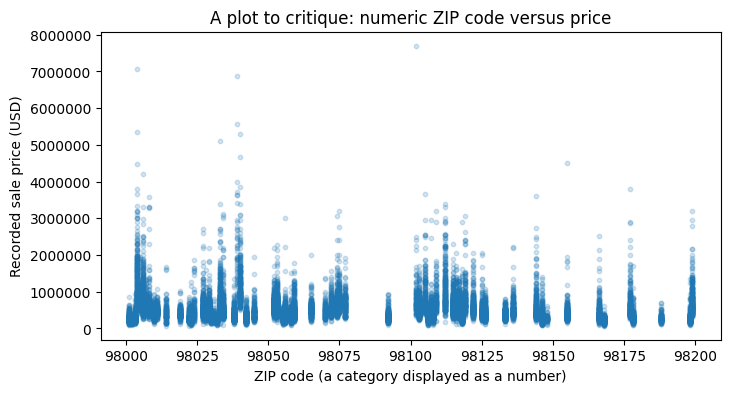

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(houses["zipcode"], houses["price"], s=10, alpha=0.2)
ax.set_xlabel("ZIP code (a category displayed as a number)")
ax.set_ylabel("Recorded sale price (USD)")
ax.set_title("A plot to critique: numeric ZIP code versus price")
ax.ticklabel_format(style="plain", axis="both", useOffset=False)
plt.show()

_Your critique:_

**Try an alternative:** select three ZIP codes with many recorded sales and
compare their price distributions using `subset.boxplot(column="price", by="zipcode")`.
A selection pattern is `houses.loc[houses["zipcode"].isin(chosen_codes)].copy()`,
where `chosen_codes` is your list of three codes. Report the group sizes.

_Your comparison:_

In [ ]:
# Optional TODO: choose three ZIP codes, create a subset, and compare distributions.
# Hint: houses["zipcode"].value_counts().head() helps find well-represented groups.

### B. Explore locations using coordinates

Run this worked example. Longitude is on the horizontal axis, latitude on the
vertical axis, and colour represents grade. This is a coordinate plot, not a
street map; numerical steps in latitude and longitude are not equal distances.

Describe a visible spatial pattern, then state a limitation. Dense clusters
indicate more **recorded sales**, and do not by themselves identify a city centre
or prove that most houses in an area have a particular grade.

Text(0.5, 0, 'Longitude (degrees)')

Text(0, 0.5, 'Latitude (degrees)')

Text(0.5, 1.0, 'Locations of recorded house sales, coloured by grade')

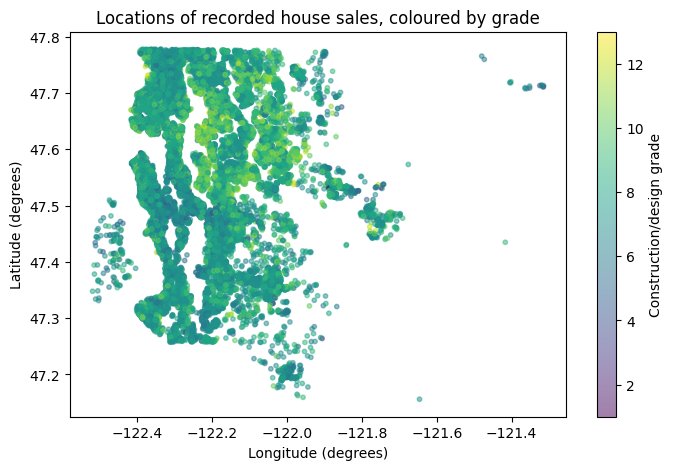

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
points = ax.scatter(houses["long"], houses["lat"], c=houses["grade"], cmap="viridis", s=10, alpha=0.5)
fig.colorbar(points, ax=ax, label="Construction/design grade")
ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
ax.set_title("Locations of recorded house sales, coloured by grade")
plt.show()

_Your observation and limitation:_

### C. Compare two categorical variables

Start with a **contingency table**: each cell counts records with one combination
of waterfront status and condition rating. The second table shows proportions
**within each waterfront group**, so each row sums to 1. Always identify the
denominator when reporting a proportion; a group count is not a population risk.

A **mosaic plot** represents combinations with rectangles whose areas correspond
to their counts. It needs the optional `statsmodels` package. The plotting lines
below are commented out so this extension adds no required dependency. If your
instructor's environment includes the package, uncomment and run them.

In [ ]:
category_counts = pd.crosstab(houses["waterfront"], houses["condition"])
print("Counts (waterfront: 0 = no, 1 = yes):")
print(category_counts)
print("Proportions within each waterfront group:")
print(pd.crosstab(houses["waterfront"], houses["condition"], normalize="index").round(3))

# Optional mosaic plot, if statsmodels is installed:
# from statsmodels.graphics.mosaicplot import mosaic
# fig, rectangles = mosaic(houses, ["waterfront", "condition"])
# fig.set_size_inches(8, 5)
# fig.axes[0].set_title("Recorded sales by waterfront status and condition")
# plt.show()

Counts (waterfront: 0 = no, 1 = yes):
condition    1    2      3     4     5
waterfront                            
0           29  171  13940  5629  1681
1            1    1     91    50    20
Proportions within each waterfront group:
condition       1      2      3      4      5
waterfront                                   
0           0.001  0.008  0.650  0.262  0.078
1           0.006  0.006  0.558  0.307  0.123


Which combination has the most recorded sales? Compare the proportion of
condition-5 sales within each waterfront group. Report both group sizes and
explain why comparing counts alone could be misleading.

_Your answer:_